# Waves around Greece, the next six days 🌊
### ECMWF free & open data · wave model · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/greece/waves_forecast.ipynb)

ECMWF's wave model forecasts the sea state worldwide, and it is **open data**: no login, no fee.
This notebook pulls the latest six-day forecast of **significant wave height** (roughly the height of the biggest third of
the waves), finds the stormiest moment around Greece, and maps it with arrows showing where the waves are heading.

*In Google Colab? Press **Runtime → Run all**. Nothing to install, no account needed.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the area

In [3]:
AREA  = [42.0, 18.5, 33.5, 30.5]           # north, west, south, east: Ionian, Aegean, Cretan and Libyan Seas
STEPS = list(range(0, 145, 6))             # every 6 hours, six days ahead
CITIES = [("Athens", 37.984, 23.728), ("Thessaloniki", 40.640, 22.944), ("Patras", 38.246, 21.735),
          ("Heraklion", 35.339, 25.144), ("Rhodes", 36.434, 28.217)]

def label_cities(chart):
    for name, la, lo in CITIES:
        chart.scatter(x=[lo], y=[la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10)
        chart.ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                      color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get the wave forecast (ECMWF open data)

In [4]:
fc = ekd.from_source("ecmwf-open-data", stream="wave", type="fc", param=["swh", "mwd"], step=STEPS)
ds = fc.to_xarray()
ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180).sortby("longitude")
ds = ds.sel(latitude=slice(AREA[0], AREA[2]), longitude=slice(AREA[1], AREA[3]))
sdim = "step" if "step" in ds.swh.dims else [d for d in ds.swh.dims if d not in ("latitude", "longitude")][0]
storm = int(ds.swh.mean(["latitude", "longitude"]).argmax())     # the stormiest moment over the whole sea
swh, mwd = ds.swh.isel({sdim: storm}), ds.mwd.isel({sdim: storm})
md0 = fc.to_fieldlist()[0].metadata
run = dt.datetime.strptime(f"{md0('dataDate')}{int(md0('dataTime')):04d}", "%Y%m%d%H%M")     # run time from the GRIB header
valid = run + dt.timedelta(hours=STEPS[storm])
print(f"Forecast from {run:%d %B %Y %H} UTC. Stormiest: {valid:%A %d %B %H}:00 UTC, highest waves {float(swh.max()):.1f} m")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Forecast from 19 November 2026 06 UTC. Stormiest: Monday 23 November 18:00 UTC, highest waves 2.6 m


## 3 · Map it

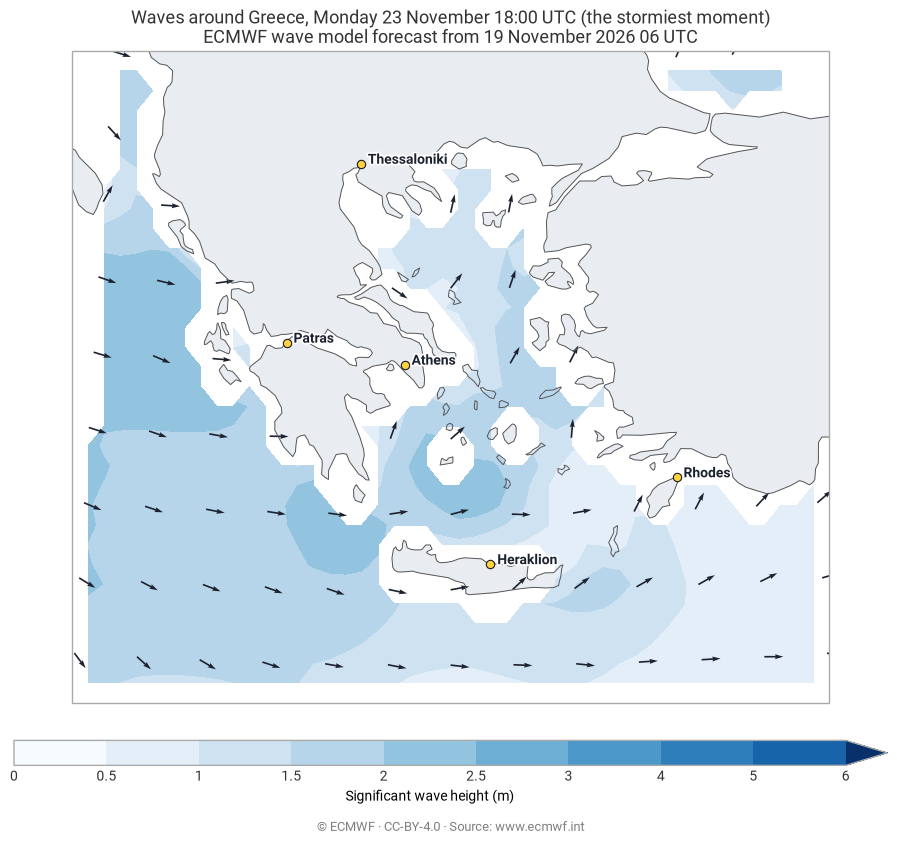

In [5]:
style = ekp.styles.Style(levels=[0, 0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6], colors="Blues", extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(11, 8))
chart.contourf(swh, style=style)
chart.land(color="#e9ecf1"); chart.coastlines(linewidth=0.7)
# arrows point where the waves are going (mwd is the direction they come from)
th = np.radians(mwd.values[::4, ::4]); lo, la = np.meshgrid(mwd.longitude.values[::4], mwd.latitude.values[::4])
chart.ax.quiver(lo, la, -np.sin(th), -np.cos(th), transform=ccrs.PlateCarree(), color="#1d2230", scale=40, width=0.0022)
label_cities(chart)
chart.legend(label="Significant wave height (m)")
chart.title(f"Waves around Greece, {valid:%A %d %B %H}:00 UTC (the stormiest moment)\n"
            f"ECMWF wave model forecast from {run:%d %B %Y %H} UTC", fontsize=13)
chart.attribution("© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int")
chart.save("waves_forecast.png")
chart.show()

## 4 · Your turn 🌍

- **A different moment:** set `storm = 0` (now) or any index into `STEPS`, then re-run step 3.
- **Wave period:** add `"mwp"` to `param` and map how long the waves are.
- **Anywhere else:** change `AREA`, for example `[62, -12, 48, 5]` for the North Sea and the British Isles.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)